# What Does a New Asteroid's First Night Tell Us? Orbits from One, Two and Three Tracklets

*Matthew Payne*

When a survey finds a moving object that might be a near-Earth object (NEO), its observations are posted on the Minor Planet Center's [NEO Confirmation Page](https://minorplanetcenter.net/iau/NEO/toconfirm_tabular.html) (NEOCP), so that other observers can find it again. At that point all anyone has is a *tracklet*: a few positions on the sky taken over an hour or so. A tracklet gives a position and a rate of motion, but not the distance to the object or how fast that distance is changing. Infinitely many orbits fit it.

This notebook is about that family of orbits: how to find it, how to picture it, and how it collapses as more tracklets arrive. It is the first of a series of notebooks on how orbital uncertainty grows, shrinks and changes shape, and on how it looks from different places; the orbit machinery is a small shared toolkit, `orbunc`, in this repository, built on the [ASSIST](https://github.com/matthewholman/assist) ephemeris-quality integrator.

Our example is real: the discovery of **2024 YR4**, the asteroid whose estimated chance of hitting the Earth in 2032 rose to about 3% in February 2025, before further observations ruled an impact out. We use the observations that were actually reported, and the MPC's present-day orbit, fitted to all observations over two years, as the truth against which to judge each step.

We will:

1. Fetch the observations of 2024 YR4 and pick out the discovery tracklet and two follow-up tracklets.
2. Reduce a tracklet to an *attributable*, and map out its *admissible region*: every distance and radial velocity that gives a sensible orbit.
3. Use *systematic ranging* to score every part of the admissible region against the observations, and see why YR4's discovery tracklet already pinned down its distance.
4. Compare with the MPC's NEO classifier, digest2.
5. Add the second and third tracklets, and follow the family of orbits as it collapses: in distance, in orbital elements, and as a "spray" of possible orbits.
6. Turn the family of orbits into what an observer needs: where to point the telescope.
7. Repeat the exercise for a main-belt asteroid, where one tracklet says much less, and see how much the answer then depends on assumptions.

**Requirements:** `numpy`, `matplotlib`, `astropy`, `assist`, `rebound`, `requests`, `digest2`, and the `orbunc` toolkit in this repository (`pip install -e ./orbunc` from the repository root). ASSIST needs two JPL ephemeris files (about 720 MB); `orbunc` looks for them in the folder named by the environment variable `ASSIST_DIR`, or downloads them to `~/.orbunc` on first use. Observations and orbits from the MPC are cached in `data/`.

**Run time:** about ten minutes on a laptop; about five minutes with `QUICK = True`.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
from astropy.time import Time

from orbunc import ephem, fit, frames, mpc, predict, ranging, sky
import neocp   # helper module in this folder: data selection, the tracklet sequence, figures

QUICK = False
GRID = dict(n_s=30, n_rd=12) if QUICK else dict(n_s=60, n_rd=24)   # ranging grid sizes
N_DRAW = 300 if QUICK else 1000                                     # orbits drawn per stage
rng = np.random.default_rng(2024)
ARCSEC, DEG = frames.ARCSEC, np.pi / 180

ephem.get_ephem()   # loads (or downloads) the JPL planetary and asteroid ephemerides
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. The observations

### 1.1 Fetch, and check the toolkit

We fetch every optical observation of 2024 YR4 from the MPC's observations API, in the ADES format, and the MPC's current orbit, with its covariance, from the orbits API. Both are cached in `data/`, so the notebook gives the same answer when re-run (delete the folder to fetch afresh).

Before trusting the toolkit with anything subtle, a test of the whole chain: propagate the MPC orbit with ASSIST to the time of every observation, compute where each observatory should have seen the asteroid (allowing for light travel time and the observatory's position on the rotating Earth), and compare with what was measured. If the time scales, reference frames or observatory positions were wrong, the residuals would be arcseconds or more.

In [2]:
obs, (t_orb, x_orb, cov_orb) = neocp.load("2024 YR4")
print(f"{len(obs)} ground-based observations from {len(np.unique(obs.stn))} observatories, "
      f"{Time(obs.jd_utc[0], format='jd').iso[:10]} to {Time(obs.jd_utc[-1], format='jd').iso[:10]}")

res = predict.residuals(x_orb[None], t_orb, obs)[0] / ARCSEC
print(f"residuals of the MPC orbit: median |O-C| per coordinate = {np.median(np.abs(res)):.3f} arcsec, "
      f"mean (RA cos Dec, Dec) = ({res[:, 0].mean():+.3f}, {res[:, 1].mean():+.3f}) arcsec")

492 ground-based observations from 62 observatories, 2024-12-25 to 2025-03-23
residuals of the MPC orbit: median |O-C| per coordinate = 0.073 arcsec, mean (RA cos Dec, Dec) = (-0.020, +0.025) arcsec


The residuals are a tenth of an arcsecond or so, the typical quality of modern astrometry, with no systematic offset. The machinery reproduces the MPC's own fit.

### 1.2 Three tracklets

ATLAS (observatory code W68, Chile) reported YR4 on 2024 December 27: four positions in 53 minutes. Many observatories observed it within hours, although some of those observations reached the MPC only weeks later. To mimic how the picture develops night by night, we take just two follow-up tracklets, from the Catalina Sky Survey (703, Arizona) one day later and from Sandlot Observatory (H36) two days later; according to the MPC's records, all three tracklets were submitted within about half an hour of being taken, so this is a sequence that orbit computers really saw. (There were also earlier, pre-discovery observations on December 25 and 26, submitted later; we ignore those.)

first observation (UTC)  station  obs  span (h)  sigma (arcsec)
2024-12-27 05:42             W68    4      0.88            0.20
2024-12-28 08:18             703    4      0.16            0.22
2024-12-29 06:37             H36    3      0.22            0.20


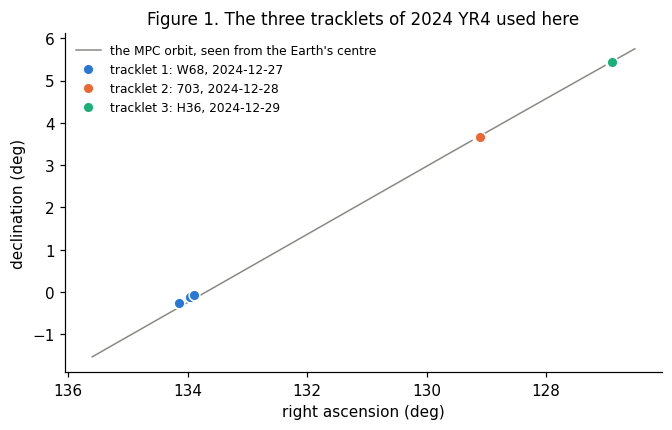

In [3]:
SIGMA_FLOOR = 0.2   # arcsec: the smallest uncertainty we accept for any observation (Section 1.3)
obs = obs.with_floor(SIGMA_FLOOR)
TRACKLETS = ["00000IVTma", "00000IVnqT", "00000IW3Ek"]   # ADES tracklet ids: W68, 703, H36
groups = [np.where(obs.trk == k)[0] for k in TRACKLETS]
neocp.tracklet_table(obs, groups)

t_all = np.linspace(obs.t[groups[0]].min() - 0.2, obs.t[groups[2]].max() + 0.2, 300)
ra_true, dec_true, _ = predict.predict(x_orb[None], t_orb, t_all, ephem.body_state("earth", t_all))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.degrees(ra_true[0]), np.degrees(dec_true[0]), color=neocp.MUTED, lw=1, label="the MPC orbit, seen from the Earth's centre")
for g, c, k in zip(groups, neocp.STAGE_COLOURS, range(3)):
    ax.plot(np.degrees(obs.ra[g]), np.degrees(obs.dec[g]), "o", color=c, ms=7, mec="white",
            label=f"tracklet {k + 1}: {obs.stn[g[0]]}, {Time(obs.jd_utc[g[0]], format='jd').iso[:10]}")
ax.invert_xaxis()
ax.set_xlabel("right ascension (deg)")
ax.set_ylabel("declination (deg)")
ax.legend(fontsize=8, frameon=False)
ax.set_title("Figure 1. The three tracklets of 2024 YR4 used here", fontsize=11)
plt.show()

YR4 was moving fast, about 9° per day. (The tracklets lie slightly off the curve because the curve is drawn as seen from the Earth's centre; each observatory sees the asteroid displaced by parallax. That displacement will matter.)

### 1.3 How far to trust the error bars

Every observation comes with the observer's estimate of its uncertainty, and the statistical weight of an observation is set by it. Those estimates usually describe the random scatter within a tracklet, but not errors that the whole tracklet shares, such as an error in the star catalogue in that patch of sky or in the clock; such errors can be as large as the scatter. Orbit computers therefore do not take the reported uncertainties at face value, but assign weights from statistical analyses of how real observations scatter about good orbits (Vereš et al. 2017). We use the simplest version of that idea: no observation is given an uncertainty below 0.2 arcsec. Section 6 shows what goes wrong without it.

## 2. From a tracklet to a family of orbits

### 2.1 The attributable

Over an hour, an asteroid's motion on the sky is very nearly a straight line at constant speed. A weighted straight-line fit of right ascension $\alpha$ and declination $\delta$ against time reduces the tracklet to four numbers at a reference time $t_0$, the *attributable* (Milani et al. 2004):

$$\mathcal{A} = (\alpha, \delta, \dot\alpha, \dot\delta).$$

An orbit needs six numbers. The two missing are the distance from the observer to the asteroid, $\rho$, and its rate of change, $\dot\rho$. Every pair $(\rho, \dot\rho)$ completes the attributable to a position and velocity, and so to an orbit: with $\hat{\mathbf u}(\alpha,\delta)$ the unit vector towards the asteroid and $\mathbf R, \dot{\mathbf R}$ the observatory's position and velocity,

$$\mathbf r = \mathbf R + \rho\,\hat{\mathbf u}, \qquad \dot{\mathbf r} = \dot{\mathbf R} + \dot\rho\,\hat{\mathbf u} + \rho\,(\dot\alpha\,\partial_\alpha\hat{\mathbf u} + \dot\delta\,\partial_\delta \hat{\mathbf u}).$$

(The toolkit also corrects for light travel time: $\mathbf r$ is where the asteroid was when the light left it.)

In [4]:
attr = ranging.fit_attributable(obs.select(groups[0]))
a, d, ad, dd = attr.x
rate = np.hypot(ad * np.cos(d), dd) / DEG
print(f"attributable at {Time(attr.jd_utc, format='jd').iso[:19]} UTC from {attr.stn}:")
print(f"  RA {np.degrees(a):.4f} deg, Dec {np.degrees(d):+.4f} deg, rate {rate:.2f} deg/day "
      f"towards position angle {np.degrees(np.arctan2(ad * np.cos(d), dd)) % 360:.0f} deg")
print("  uncertainties: position {:.2f}, {:.2f} arcsec; rates {:.1f}, {:.1f} arcsec/day".format(
      *(np.sqrt(np.diag(attr.cov)) / ARCSEC * [np.cos(d), 1, np.cos(d), 1])))
rho_true, rhodot_true = ranging.rho_rhodot_of(x_orb, t_orb, attr)
print(f"the true orbit had rho = {rho_true:.5f} au ({rho_true * frames.AU_KM / 384400:.1f} lunar distances), "
      f"rho-dot = {rhodot_true:.5f} au/day ({rhodot_true * frames.AU_KM / 86400:.1f} km/s)")

attributable at 2024-12-27 06:07:20 UTC from W68:
  RA 134.0446 deg, Dec -0.1793 deg, rate 9.11 deg/day towards position angle 306 deg
  uncertainties: position 0.10, 0.10 arcsec; rates 6.2, 6.2 arcsec/day
the true orbit had rho = 0.01719 au (6.7 lunar distances), rho-dot = 0.00744 au/day (12.9 km/s)


### 2.2 The admissible region

Not every $(\rho, \dot\rho)$ is sensible. Following Milani et al. (2004), we keep the orbits that are bound to the Sun (negative heliocentric energy) and not bound to the Earth (we drop orbits inside the Earth's Hill sphere with negative geocentric energy, which would be satellites of the Earth). We also drop orbits that would have hit the Earth while being observed. The heliocentric energy is quadratic in $\dot\rho$ at fixed $\rho$, so at each distance the bound orbits fill an interval of $\dot\rho$, and the region has a closed boundary. Its extent in $\rho$ is set by the rate of motion: a fast-moving object must be close, or it would be moving too fast to be bound.

### 2.3 Systematic ranging

The admissible region contains every orbit compatible with the attributable. To see which of them also fit the *individual* observations, we use **systematic ranging** (Chesley 2005; Farnocchia, Chesley & Micheli 2015): cover the region with a grid of $(\rho, \dot\rho)$; at each node hold $\rho, \dot\rho$ fixed and adjust the other four parameters by least squares to fit all the observations; record the $\chi^2$. Each node is then given a probability proportional to

$$p(\rho, \dot\rho) \propto \pi(\rho, \dot\rho)\, \exp\!\left(-\tfrac{1}{2}\chi^2(\rho, \dot\rho)\right),$$

where $\pi$ is a prior. We use a prior uniform in $\rho$ and $\dot\rho$ over the admissible region; we return to that choice in Section 6.1. (Related approaches are statistical ranging, Virtanen, Muinonen & Bowell 2001, and the admissible-region methods used by NEOCC, Spoto et al. 2018.)

The toolkit's version follows the bottom of the $\chi^2$ valley: it first finds, for each $\rho$, the best $\dot\rho$ and the width of the valley in $\dot\rho$, refines the grid in $\rho$ where the valley floor is near its minimum, and then places nodes across the valley. With one tracklet the valley is as wide as the admissible region; with several it becomes very narrow, and a fixed grid would miss it entirely. Every fit propagates thousands of trial orbits through the real Solar System with ASSIST, as test particles in one integration.

Here is the result for the discovery tracklet, and, to compare, for only its first two positions, taken 3 minutes apart.

9504 nodes fitted in 34 s


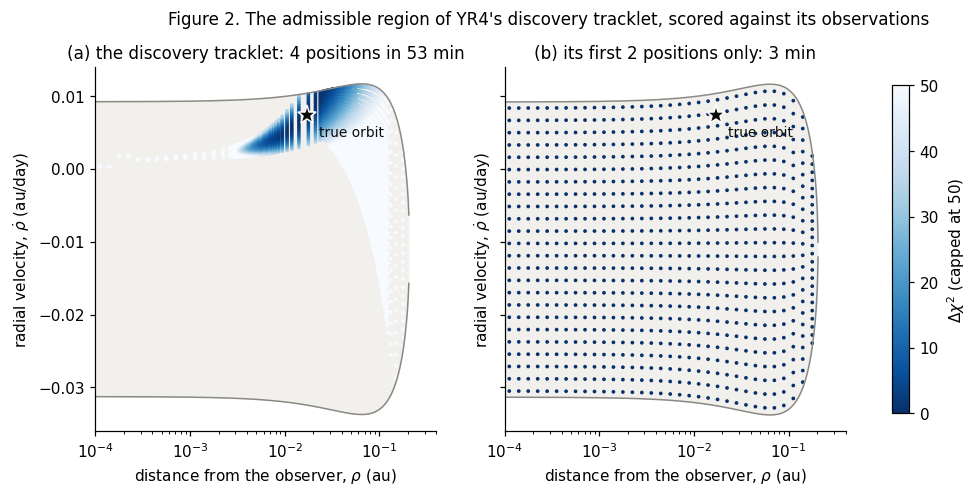

4 positions: rho 5%, 50%, 95% = 0.0106, 0.0178, 0.0280 au
2 positions: rho 5%, 50%, 95% = 0.0089, 0.0891, 0.1778 au


In [5]:
T1 = obs.select(groups[0])
T1_short = obs.select(groups[0][:2])
attr_short = ranging.fit_attributable(T1_short)
tic = time.time()
full = ranging.systematic_ranging(attr, T1, dchi2_nodes=None, **GRID)               # keep nodes everywhere, for the map
full_short = ranging.systematic_ranging(attr_short, T1_short, dchi2_nodes=None, **GRID)
print(f"{len(full) + len(full_short)} nodes fitted in {time.time() - tic:.0f} s")

fig, axs = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True)
sc = neocp.plot_admissible(axs[0], attr, full, (rho_true, rhodot_true), "(a) the discovery tracklet: 4 positions in 53 min")
neocp.plot_admissible(axs[1], attr_short, full_short, (rho_true, rhodot_true), "(b) its first 2 positions only: 3 min")
for ax in axs:
    ax.set_xlim(1e-4, 0.4)
fig.colorbar(sc, ax=axs, label=r"$\Delta\chi^2$ (capped at 50)", shrink=0.9)
fig.suptitle("Figure 2. The admissible region of YR4's discovery tracklet, scored against its observations", fontsize=11, y=1.0)
plt.show()

for label, nodes, at in [("4 positions", full, attr), ("2 positions", full_short, attr_short)]:
    w = ranging.weights(nodes, at)
    q = neocp.wquantile(nodes.rho, w, [0.05, 0.5, 0.95])
    print(f"{label}: rho 5%, 50%, 95% = {q[0]:.4f}, {q[1]:.4f}, {q[2]:.4f} au")

The pale area is the admissible region; the dots are the ranging nodes, dark where they fit well. With only two positions (b), every node fits perfectly: two positions determine an attributable exactly and say nothing about distance. The region itself is bounded, though: YR4 moved so fast that it had to be within about 0.2 au to be bound to the Sun.

With all four positions (a), most of the region is ruled out, and the fit picks out the right distance, about 0.017 au. Why does a 53-minute tracklet constrain distance at all? Because the observatory is not standing still: it is carried around the Earth's axis at up to 0.46 km/s. Over an hour that circular motion bends the line of sight by an amount that depends on distance, like a slow, sideways version of parallax. The bending is about $\frac{1}{2}\omega^2 R_\oplus \cos\phi\, T^2/\rho$, for rotation rate $\omega$, latitude $\phi$ and duration $T$:

In [6]:
omega = 2 * np.pi / 0.99727   # rad per day
T = np.ptp(T1.t)
lat = np.arcsin(-0.504269 / np.hypot(0.862845, 0.504269))   # W68 parallax constants
for rho in [rho_true, 0.1, 2.0]:
    bend = 0.5 * omega ** 2 * frames.R_EARTH_KM * np.cos(lat) * T ** 2 / (rho * frames.AU_KM)
    print(f"rho = {rho:6.3f} au: diurnal curvature over {T * 24:.2f} h ~ {bend / ARCSEC:7.2f} arcsec")
print(f"compare: astrometric uncertainty of these observations ~ {np.median(T1.sig_ra):.2f} arcsec")

rho =  0.017 au: diurnal curvature over 0.88 h ~   11.73 arcsec
rho =  0.100 au: diurnal curvature over 0.88 h ~    2.02 arcsec
rho =  2.000 au: diurnal curvature over 0.88 h ~    0.10 arcsec
compare: astrometric uncertainty of these observations ~ 0.20 arcsec


For an object as close as YR4 was, the curvature is tens of times the measurement error, and the tracklet alone determines its distance to about 30%. For a main-belt asteroid at 2 au the curvature is below the noise, and the tracklet says almost nothing about distance (Section 6). Most NEOCP objects are further away when found than YR4 was, and for them the first night is closer to panel (b) than (a).

## 3. What digest2 makes of it

The MPC decides which tracklets to post on the NEOCP with **digest2** (Keys et al. 2019), which scores a tracklet by how likely it is to be an NEO. digest2 also generates trial orbits over a range of distances and directions of motion, but in a different spirit: it sweeps systematically through distances to find which bins of a population model of the Solar System the tracklet could belong to, and weights those bins by how many known and predicted objects they contain. Its trial orbits are a census of *possible* orbits, not a sample of probable ones, and it does not model the diurnal curvature.

digest2: NEO score 100 (raw 100); 50767 trial orbits; their distances span 0.050-0.196 au


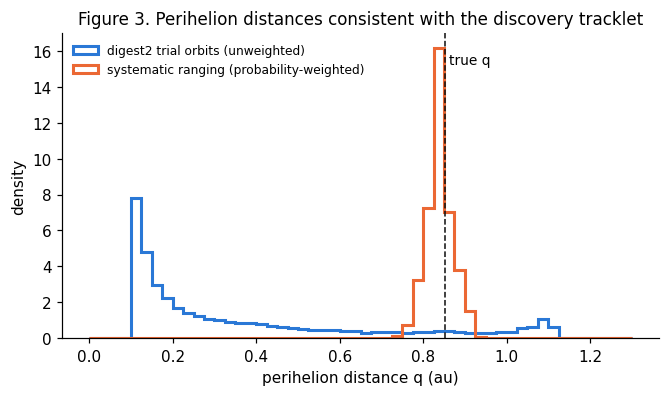

In [7]:
d2 = neocp.digest2_tracklet(obs, groups[0])
el_d2 = d2.orbit_elements
print(f"digest2: NEO score {d2.noid.NEO:.0f} (raw {d2.raw.NEO:.0f}); {len(el_d2['q'])} trial orbits; "
      f"their distances span {el_d2['d'].min():.3f}-{el_d2['d'].max():.3f} au")

w1 = ranging.weights(full, attr)
el1 = frames.elements(frames.bary_eq_to_helio_ec(np.nan_to_num(full.states), attr.t))
bins = np.linspace(0, 1.3, 53)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(el_d2["q"], bins=bins, density=True, histtype="step", lw=2, color=neocp.STAGE_COLOURS[0], label="digest2 trial orbits (unweighted)")
ax.hist(el1["q"], bins=bins, weights=w1, density=True, histtype="step", lw=2, color=neocp.STAGE_COLOURS[1], label="systematic ranging (probability-weighted)")
ax.axvline(x_q := frames.elements(frames.bary_eq_to_helio_ec(x_orb[None], t_orb))["q"][0], color=neocp.INK, ls="--", lw=1)
ax.text(x_q + 0.01, ax.get_ylim()[1] * 0.9, "true q", fontsize=9)
ax.set_xlabel("perihelion distance q (au)")
ax.set_ylabel("density")
ax.legend(fontsize=8, frameon=False, loc="upper left")
ax.set_title("Figure 3. Perihelion distances consistent with the discovery tracklet", fontsize=11)
plt.show()

Both say "NEO" without hesitation: all of digest2's trial orbits, and all of the ranging probability, lie at perihelion distances below 1.3 au. They differ in how the orbits are spread: digest2 explores everything compatible with the attributable, while ranging, using the curvature, concentrates on orbits near the true one.

## 4. Adding tracklets

Now we repeat the ranging with the first one, two and three tracklets. The attributable, and so the coordinates $(\rho, \dot\rho)$, stay those of the discovery tracklet, so the three results can be compared directly.

In [8]:
tic = time.time()
stages = neocp.sequence(attr, obs, groups, **GRID)
print(f"ranging with 1, 2, 3 tracklets: {time.time() - tic:.0f} s")
el_true = frames.elements(frames.bary_eq_to_helio_ec(x_orb[None], t_orb))
print(f"true orbit: a = {el_true['a'][0]:.3f} au, e = {el_true['e'][0]:.3f}, i = {el_true['i'][0]:.2f} deg; "
      f"rho = {rho_true:.5f} au, rho-dot = {rhodot_true:.6f} au/day\n")
print(f"{'tracklets':>9s} {'obs':>4s} {'best chi2':>9s} {'rho (au)':>20s} {'a (au)':>15s} {'e':>15s} {'i (deg)':>13s} {'P(NEO)':>7s}")
for s in stages:
    w, el, n = s["w"], s["el"], s["nodes"]
    f = lambda x: "{:.4g} ± {:.2g}".format(*neocp.wmean_sd(x, w))
    print(f"{s['n']:9d} {len(s['obs']):4d} {np.min(n.chi2):9.1f} {f(n.rho):>20s} {f(el['a']):>15s} {f(el['e']):>15s} {f(el['i']):>13s} "
          f"{neocp.group_probabilities(el, w)['NEO']:7.3f}")
qa = neocp.wquantile(stages[0]["el"]["a"], stages[0]["w"], [0.05, 0.95])
print(f"\nwith one tracklet, 90% of the probability has {qa[0]:.2f} < a < {qa[1]:.1f} au")

ranging with 1, 2, 3 tracklets: 128 s
true orbit: a = 2.516 au, e = 0.661, i = 3.41 deg; rho = 0.01719 au, rho-dot = 0.007439 au/day

tracklets  obs best chi2             rho (au)          a (au)               e       i (deg)  P(NEO)
        1    4       0.1     0.01887 ± 0.0054      7.009 ± 11   0.7235 ± 0.17  3.582 ± 0.66   1.000
        2    8       1.5    0.01719 ± 5.3e-05   2.522 ± 0.021  0.6623 ± 0.003 3.412 ± 0.013   1.000
        3   11       2.0    0.01719 ± 1.8e-05  2.522 ± 0.0052 0.6625 ± 0.00074 3.413 ± 0.0029   1.000

with one tracklet, 90% of the probability has 1.61 < a < 42.3 au


The best $\chi^2$ is well below the number of measurements: these are good observations, and the 0.2 arcsec floor gives them less weight than they probably deserve, so the uncertainties here are, if anything, conservative. The distance at discovery tightens from about 30% (one tracklet) to about 0.5% (two) and 0.1% (three); the semi-major axis, from a range spanning the inner Solar System and beyond, to about 1% and then 0.2%. The true values lie within the stated uncertainties at each stage.

Figure 4 shows why: the bottom of the $\chi^2$ valley, the best $\chi^2$ at each distance, as tracklets are added.

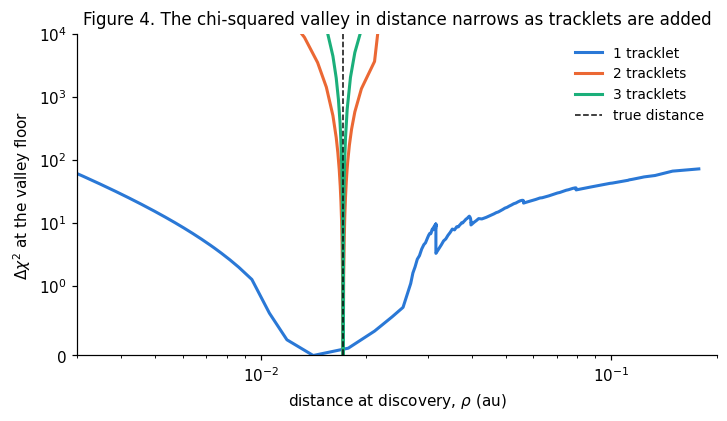

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for s, c in zip(stages, neocp.STAGE_COLOURS):
    p = s["nodes"].profile
    ok = np.isfinite(p["chi2"])
    ax.plot(p["rho"][ok], p["chi2"][ok] - p["chi2"][ok].min(), color=c, lw=2, label=f"{s['n']} tracklet" + "s" * (s["n"] > 1))
ax.axvline(rho_true, color=neocp.INK, ls="--", lw=1, label="true distance")
ax.set_xscale("log")
ax.set_yscale("symlog", linthresh=1)
ax.set_xlim(3e-3, 0.2)
ax.set_ylim(0, 1e4)
ax.set_xlabel(r"distance at discovery, $\rho$ (au)")
ax.set_ylabel(r"$\Delta\chi^2$ at the valley floor")
ax.legend(fontsize=9, frameon=False, loc="upper right")
ax.set_title("Figure 4. The chi-squared valley in distance narrows as tracklets are added", fontsize=11)
plt.show()

### 4.1 The spray of orbits

A probability over $(\rho, \dot\rho)$ is abstract. Drawing orbits from it, and drawing those orbits, is not. To draw an orbit, the toolkit picks a node according to its probability and a random point within its cell, refits the attributable there, corrects the choice by how well that point really fits (importance sampling), and finally adds the uncertainty of the attributable itself. Figure 5 shows a random draw after each tracklet, seen from above the plane of the Earth's orbit, coloured by orbit class.

drew 1000 orbits per stage in 35 s


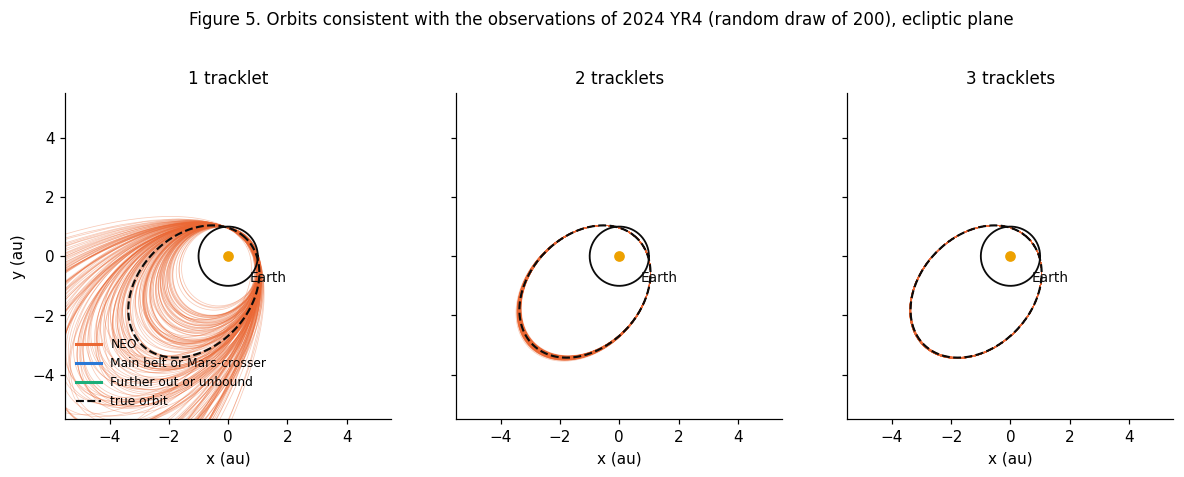

In [10]:
tic = time.time()
draws = [neocp.draw(s, attr, N_DRAW, rng) for s in stages]
print(f"drew {N_DRAW} orbits per stage in {time.time() - tic:.0f} s")
fig, axs = plt.subplots(1, 3, figsize=(13, 4.6), sharey=True)
for ax, s, (X, el) in zip(axs, stages, draws):
    neocp.plot_spray(ax, el, el_true, lim=5.5, title=f"{s['n']} tracklet" + "s" * (s["n"] > 1))
axs[0].set_ylabel("y (au)")
neocp.group_legend(axs[0])
fig.suptitle("Figure 5. Orbits consistent with the observations of 2024 YR4 (random draw of 200), ecliptic plane", fontsize=11)
plt.show()

After the discovery tracklet every possible orbit crosses the Earth's orbit, but their sizes and orientations range widely; after the second night they have nearly collapsed onto the true orbit (dashed).

## 5. Where to point the telescope

What follow-up observers need is not an orbit but a place on the sky. Each drawn orbit predicts a position at any later time, and the cloud of predictions is the area to search. Figure 6 shows the predicted position of YR4 as seen from ATLAS Chile on the night after the third tracklet (2024 December 30, 06:00 UTC), from each stage.

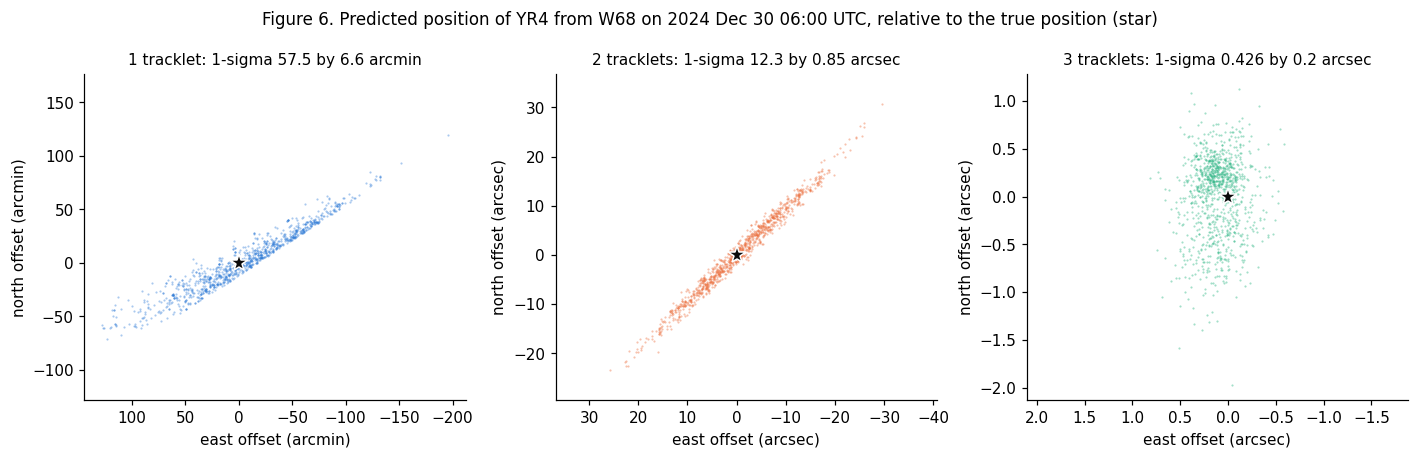

In [11]:
JD_NEXT = Time("2024-12-30T06:00:00", scale="utc").jd
ra_t, dec_t = sky.sky_positions(x_orb[None], t_orb, [JD_NEXT], "W68")
fig, axs = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, s, (X, el), c in zip(axs, stages, draws, neocp.STAGE_COLOURS):
    ra, dec = sky.sky_positions(X, attr.t, [JD_NEXT], "W68")
    unit, name = (60 * ARCSEC, "arcmin") if s["n"] == 1 else (ARCSEC, "arcsec")
    e, n = sky.offsets(ra[:, 0], dec[:, 0], ra_t[0, 0], dec_t[0, 0], unit=unit)
    ax.scatter(e, n, s=2, color=c, alpha=0.4, lw=0, rasterized=True)
    ax.plot(0, 0, marker="*", color=neocp.INK, ms=12, mec="white", ls="none")
    ax.invert_xaxis()
    ax.set_xlabel(f"east offset ({name})")
    ax.set_ylabel(f"north offset ({name})")
    sd = np.sqrt(np.linalg.eigvalsh(np.cov(np.stack([e, n]))))
    ax.set_title(f"{s['n']} tracklet" + "s" * (s["n"] > 1) + f": 1-sigma {sd[1]:.3g} by {sd[0]:.2g} {name}", fontsize=10)
    ax.set_aspect("equal", adjustable="datalim")
fig.suptitle("Figure 6. Predicted position of YR4 from W68 on 2024 Dec 30 06:00 UTC, relative to the true position (star)", fontsize=11)
plt.tight_layout()
plt.show()

From the discovery tracklet alone, the predicted position three days later is spread over a degree or more, elongated along the direction of motion (the *line of variations*): different distances mean different speeds across the sky, and the main uncertainty is how far along its track the asteroid has gone. After the second tracklet the spread is about 15 arcseconds, and after the third, under an arcsecond. The first follow-up is the hardest and the most important; NEOCP objects that are not recovered within a night or two are often lost.

## 6. A main-belt asteroid on the NEOCP

Many objects posted to the NEOCP turn out to be main-belt asteroids. To see that side, take the main-belt asteroid (10606) Crocco (the asteroid followed in the [HelioLinC notebook](../heliolinc/heliolinc.ipynb)) and pretend that we have never seen it before: one tracklet from the Mount Lemmon Survey (G96) on 2026 January 21, then tracklets from Purple Mountain Observatory's XuYi station (D29) two days later and from ATLAS on Haleakala (T05) eight days later.

First, the error bars again (Section 1.3). Here are the true orbit and a least-squares fit to the three tracklets, judged with the uncertainties as reported and with our 0.2 arcsec floor:

In [12]:
obs_c, (t_c, x_c, _) = neocp.load("10606", start="2026-01-01", end="2026-03-01")   # only the weeks we need
groups_c = [np.where(obs_c.trk == k)[0] for k in ["000000ICnmr0", "000000IDBFm0", "000000IDuBH0"]]
neocp.tracklet_table(obs_c, groups_c)
O3 = obs_c.select(np.concatenate(groups_c))
t_ref = O3.t[0]
x_c_ref = ephem.propagate(x_c[None], t_c, [t_ref])[0, 0]
for label, O in [("as reported", O3), (f"with the {SIGMA_FLOOR} arcsec floor", O3.with_floor(SIGMA_FLOOR))]:
    f = fit.fit_orbit(x_c_ref, t_ref, O)
    dx = f.state - x_c_ref
    print(f"uncertainties {label}: chi2 of the true orbit {predict.chi2(x_c[None], t_c, O)[0]:.0f}, of the best fit {f.chi2:.0f}, "
          f"for {2 * len(O)} measurements; true orbit at Mahalanobis distance^2 {dx @ np.linalg.solve(f.cov, dx):.0f} from the fit")

first observation (UTC)  station  obs  span (h)  sigma (arcsec)
2026-01-21 07:16             G96    4      0.38            0.08
2026-01-23 14:40             D29    6      0.70            0.07
2026-01-29 09:29             T05    4      0.40            0.47
uncertainties as reported: chi2 of the true orbit 215, of the best fit 144, for 28 measurements; true orbit at Mahalanobis distance^2 71 from the fit
uncertainties with the 0.2 arcsec floor: chi2 of the true orbit 25, of the best fit 20, for 28 measurements; true orbit at Mahalanobis distance^2 6 from the fit


With the uncertainties as reported, even the *true* orbit fits these three tracklets badly: the D29 tracklet, reported as good to 0.07 arcsec, sits about 0.1 arcsec from where Crocco really was. An orbit fitted with such weights is overconfident: the true orbit lies far outside the fit's formal uncertainty, where a Mahalanobis distance squared of about 6 would be typical for six parameters. With the floor, both are as they should be. From here on we use the floor.

In [13]:
obs_c = obs_c.with_floor(SIGMA_FLOOR)
attr_c = ranging.fit_attributable(obs_c.select(groups_c[0]))
rr_c = ranging.rho_rhodot_of(x_c, t_c, attr_c)
el_c = frames.elements(frames.bary_eq_to_helio_ec(x_c[None], t_c))
print(f"true orbit: a = {el_c['a'][0]:.3f} au, e = {el_c['e'][0]:.3f}, i = {el_c['i'][0]:.1f} deg; rho = {rr_c[0]:.3f} au; "
      f"rate of motion {np.hypot(attr_c.x[2] * np.cos(attr_c.x[1]), attr_c.x[3]) / DEG:.3f} deg/day")

tic = time.time()
full_c = ranging.systematic_ranging(attr_c, obs_c.select(groups_c[0]), dchi2_nodes=None, **GRID)
stages_c = neocp.sequence(attr_c, obs_c, groups_c, **GRID)
print(f"ranging: {time.time() - tic:.0f} s")
d2c = neocp.digest2_tracklet(obs_c, groups_c[0])
print(f"digest2 NEO score of the first tracklet: {d2c.noid.NEO:.0f} ('noid', assuming the object is not a known one); "
      f"{d2c.raw.NEO:.0f} ('raw', counting known objects too)")
for s in stages_c:
    print(f"{s['n']} tracklet(s): a = {'{:.3g} ± {:.2g}'.format(*neocp.wmean_sd(s['el']['a'], s['w']))} au; "
          + ", ".join(f"P({k}) = {v:.3f}" for k, v in neocp.group_probabilities(s['el'], s['w']).items())
          + f"; the true distance is at the {100 * s['w'][s['nodes'].rho < rr_c[0]].sum():.0f}th percentile")

true orbit: a = 3.150 au, e = 0.102, i = 17.6 deg; rho = 2.547 au; rate of motion 0.199 deg/day


ranging: 286 s


digest2 NEO score of the first tracklet: 85 ('noid', assuming the object is not a known one); 23 ('raw', counting known objects too)
1 tracklet(s): a = 10.1 ± 17 au; P(NEO) = 0.542, P(Main belt or Mars-crosser) = 0.196, P(Further out or unbound) = 0.262; the true distance is at the 37th percentile
2 tracklet(s): a = 7.68 ± 8.8 au; P(NEO) = 0.479, P(Main belt or Mars-crosser) = 0.299, P(Further out or unbound) = 0.221; the true distance is at the 20th percentile
3 tracklet(s): a = 3.15 ± 0.0019 au; P(NEO) = 0.000, P(Main belt or Mars-crosser) = 1.000, P(Further out or unbound) = 0.000; the true distance is at the 11th percentile


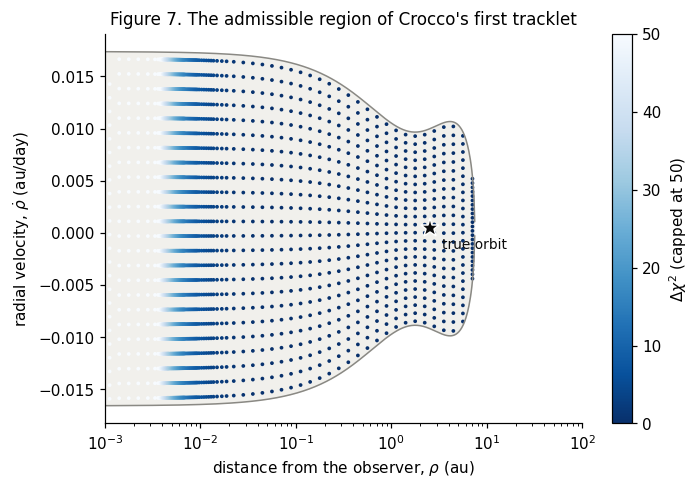

In [14]:
fig, ax = plt.subplots(figsize=(7, 4.6))
sc = neocp.plot_admissible(ax, attr_c, full_c, rr_c, "")
ax.set_xlim(1e-3, 100)
fig.colorbar(sc, ax=ax, label=r"$\Delta\chi^2$ (capped at 50)")
ax.set_title("Figure 7. The admissible region of Crocco's first tracklet", fontsize=11)
plt.show()

Crocco, at about 2.5 au, moves slowly, and its tracklet has no measurable curvature: almost every admissible orbit fits (Figure 7), from objects a few hundredths of an au away to objects in the outer Solar System; only the very closest are ruled out. The probabilities in the printout are then set by the prior rather than by the data, and the prior is a choice.

### 6.1 One line of sight, many orbits

What does "many orbits fit one tracklet" look like? A tracklet is, in effect, a line of sight: a ray from the observer out into space, along which the asteroid must lie, together with the rate at which that direction is changing. (Its four positions are four rays, but over 20 minutes they are indistinguishable at this scale.) Every orbit that fits places the asteroid somewhere on the ray at the moment of the tracklet, moving so that, seen from the observer, it drifts across the sky at exactly the measured rate. Figure 8 draws a sample of the orbits that fit Crocco's first tracklet: where each one crosses the ray, and its path for 15 days either side, coloured by its distance from the observer at the time of the tracklet.

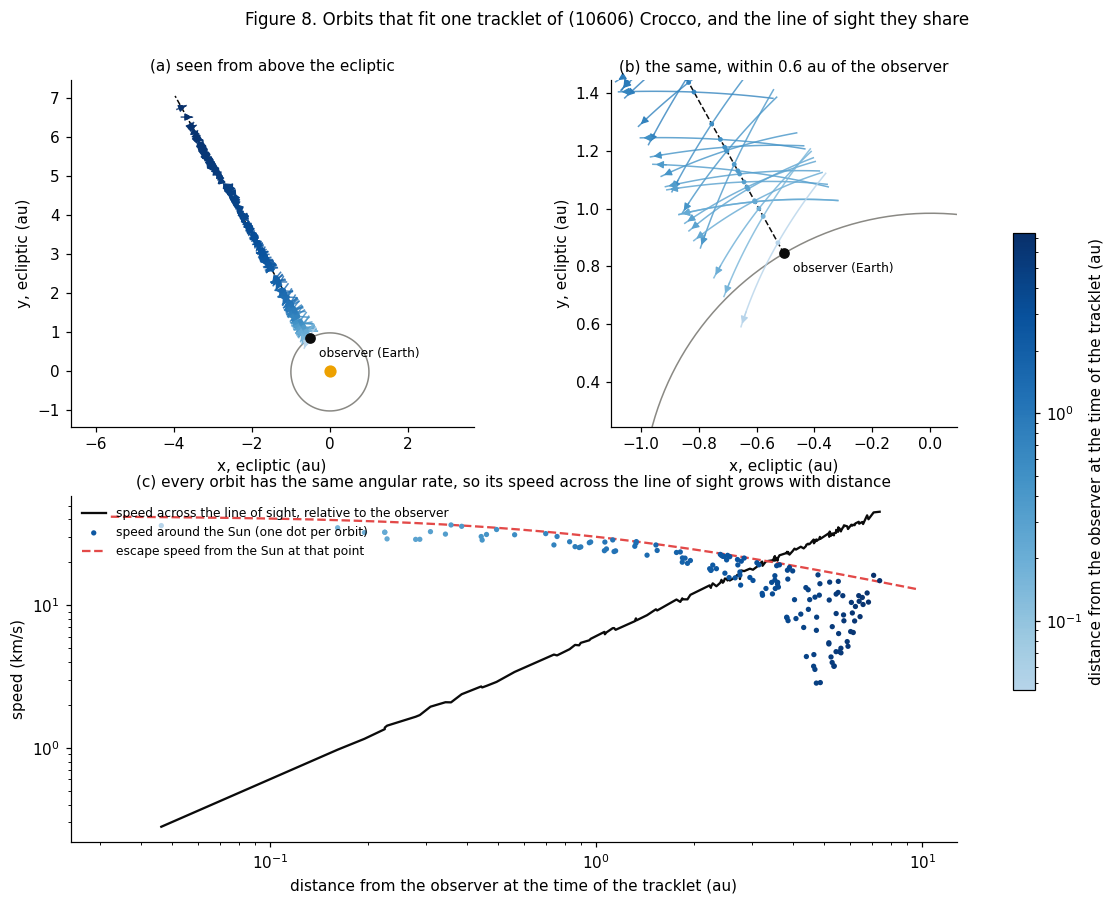

distances along the line of sight: 0.046 to 7.4 au (true: 2.55 au)


In [15]:
X_ray, el_ray = neocp.draw(stages_c[0], attr_c, N_DRAW, rng)
g = neocp.ray_geometry(attr_c, X_ray[:150])
fig, axs = neocp.plot_ray_views(g, zoom_au=0.6)
fig.suptitle("Figure 8. Orbits that fit one tracklet of (10606) Crocco, and the line of sight they share", fontsize=11, y=0.95)
plt.show()
print(f"distances along the line of sight: {g['rho'].min():.3f} to {g['rho'].max():.1f} au (true: {rr_c[0]:.2f} au)")

In (a) the orbits are strung along the line of sight out to about 7 au. In (b), close to the observer, you can see what they have in common: each crosses the ray at a different distance and in a different direction, but always so that the asteroid stays on the ray, as seen from the observer, during the hour of the tracklet. The farther along the ray, the faster the orbit must move across it to produce the same angular rate (c): the speed across the line of sight grows in proportion to distance. Close to the Earth the candidates move around the Sun much as the Earth does, at about 30 km/s; far away they must move faster and faster across the line of sight, until, beyond about 7 au, no orbit bound to the Sun can keep up. That is the outer edge of the admissible region.

The observer sees all these orbits as one point moving at one rate at the time of the tracklet. Only as time passes do they separate on the sky (Figure 9): the distant ones stay close to a straight-line extrapolation of the tracklet, while the nearby ones, whose apparent motion is dominated by the observer's own motion and their own faster orbital motion, swing away by degrees within a month.

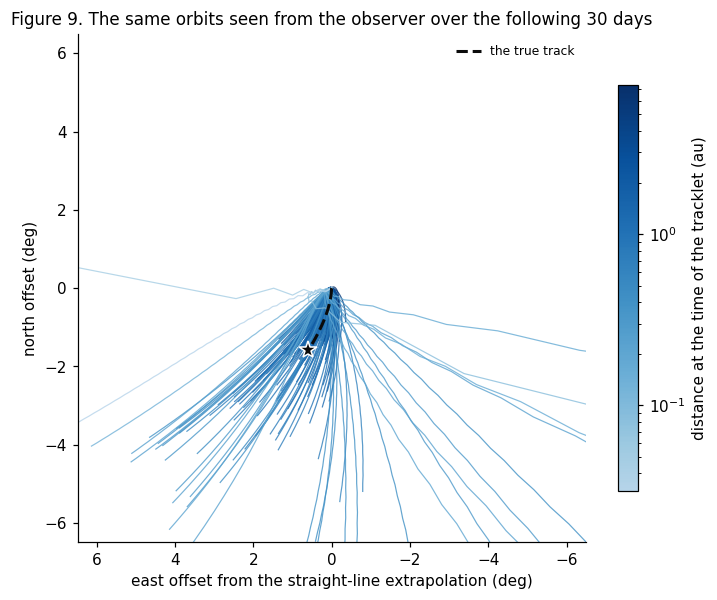

8% of the 30-day tracks end outside the plotted area


In [16]:
rho_ray = np.linalg.norm(neocp._helio_ec(X_ray[None], np.array([attr_c.t]))[0, :, :3] - g["observer"], axis=1)
fig, ax, outside = neocp.plot_sky_tracks(attr_c, X_ray[:300], rho_ray[:300], "G96", 30, x_c, t_c)
ax.set_title("Figure 9. The same orbits seen from the observer over the following 30 days", fontsize=11)
plt.show()
print(f"{outside:.0%} of the 30-day tracks end outside the plotted area")

### 6.2 More tracklets, and digest2's view

The second tracklet, two days later, rules out the close-in orbits: nothing nearer than about 1 au fits well. But it leaves the radial velocity, and so the shape of the orbit, open: from main-belt orbits to very elongated ones. Many of the elongated orbits have perihelia inside 1.3 au and so, by definition, count as NEO orbits, although the object is several au away, which is why the NEO probability is still substantial. Only the third tracklet, eight days after the first, settles that Crocco is in the main belt.

The digest2 score shows another subtlety. Its usual 'noid' score asks how likely the tracklet is to be an NEO *if it is not an object already known*; since practically every main-belt asteroid as bright as Crocco has already been found, an unknown object this bright would most likely be an NEO, and the score is high. The 'raw' score, which counts the known objects too, is lower. Tracklets are checked against the orbits of known objects before they are considered for the NEOCP, which is why the 'noid' score is the relevant one.

### 6.3 How much does the prior matter?

We have used a prior uniform in $\rho$ and $\dot\rho$. A prior uniform in $\ln\rho$ and $\dot\rho$, which gives each factor of distance equal weight, is just as defensible. When the data cannot tell the distances apart, changing the prior changes the answer, with no new data:

In [17]:
for name, st in [("2024 YR4", stages), ("(10606) Crocco", stages_c)]:
    for s in st:
        w_log = s["w"] / s["nodes"].rho
        w_log /= w_log.sum()
        p_lin = neocp.group_probabilities(s["el"], s["w"])["NEO"]
        p_log = neocp.group_probabilities(s["el"], w_log)["NEO"]
        print(f"{name:15s} {s['n']} tracklet(s): P(NEO) = {p_lin:.3f} (uniform in rho), {p_log:.3f} (uniform in ln rho)")

2024 YR4        1 tracklet(s): P(NEO) = 1.000 (uniform in rho), 1.000 (uniform in ln rho)
2024 YR4        2 tracklet(s): P(NEO) = 1.000 (uniform in rho), 1.000 (uniform in ln rho)
2024 YR4        3 tracklet(s): P(NEO) = 1.000 (uniform in rho), 1.000 (uniform in ln rho)
(10606) Crocco  1 tracklet(s): P(NEO) = 0.542 (uniform in rho), 0.756 (uniform in ln rho)
(10606) Crocco  2 tracklet(s): P(NEO) = 0.479 (uniform in rho), 0.358 (uniform in ln rho)
(10606) Crocco  3 tracklet(s): P(NEO) = 0.000 (uniform in rho), 0.000 (uniform in ln rho)


For YR4 the data decide, and the prior does not matter. For Crocco's first tracklet, the probability that it is an NEO moves when an arbitrary choice is changed; it is a statement about the prior as much as about the asteroid. This is why digest2 uses as its prior a model of the actual population of the Solar System, in which main-belt asteroids vastly outnumber NEOs. With more tracklets, the data take over.

### 6.4 When is a Gaussian good enough?

Once there are enough observations, an orbit is usually computed by least squares, and its uncertainty described by a covariance matrix: a six-dimensional Gaussian, mapped onto the sky by linearising the orbit's predictions. Ranging makes no such assumption. Figure 10 compares the two after two tracklets, a month later, for both objects.

2024 YR4: least-squares chi2 1.4 for 16 measurements; true orbit at Mahalanobis distance^2 2.5; 1-sigma spread on 2025-01-29: Gaussian (least squares) 0.713 arcmin, systematic ranging 0.747 arcmin


(10606) Crocco: least-squares chi2 13.3 for 20 measurements; true orbit at Mahalanobis distance^2 21.4; 1-sigma spread on 2026-02-23: Gaussian (least squares) 865 arcmin, systematic ranging 26.9 arcmin


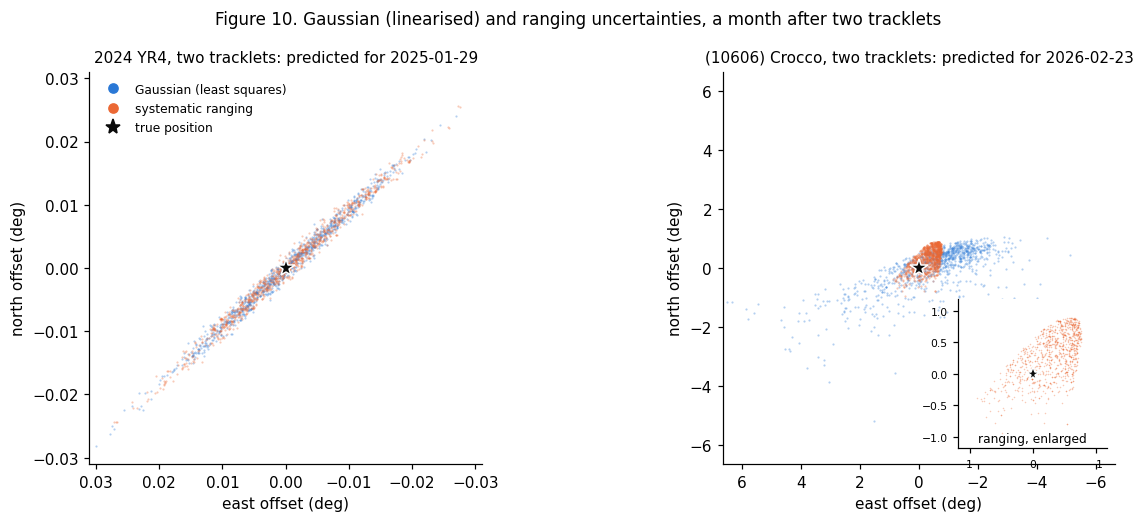

In [18]:
cases = [("2024 YR4", stages[1], attr, (t_orb, x_orb), "2025-01-29T06:00:00", "W68"),
         ("(10606) Crocco", stages_c[1], attr_c, (t_c, x_c), "2026-02-23T08:00:00", "G96")]
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (name, s, at, (tt, xt), date, stn) in zip(axs, cases):
    jd = Time(date, scale="utc").jd
    f = fit.fit_orbit(s["nodes"].states[np.argmin(s["nodes"].chi2)], at.t, s["obs"])
    dx = f.state - ephem.propagate(xt[None], tt, [at.t])[0, 0]
    clouds = {"Gaussian (least squares)": fit.sample_gaussian(f, N_DRAW, rng), "systematic ranging": neocp.draw(s, at, N_DRAW, rng)[0]}
    ra_t, dec_t = sky.sky_positions(xt[None], tt, [jd], stn)
    spread = {}
    for (label, X), c in zip(clouds.items(), neocp.STAGE_COLOURS):
        ra, dec = sky.sky_positions(X, at.t, [jd], stn)
        e, n = sky.offsets(ra[:, 0], dec[:, 0], ra_t[0, 0], dec_t[0, 0], unit=DEG)
        ax.scatter(e, n, s=2, color=c, alpha=0.35, lw=0, rasterized=True)
        spread[label] = np.sqrt(np.linalg.eigvalsh(np.cov(np.stack([e, n])))[-1])
        extent = np.percentile(np.hypot(e, n), 98)
        if label.startswith("Gaussian"):
            e_g = extent
        else:
            e_r, n_r, extent_r = e, n, extent
    ax.plot(0, 0, marker="*", color=neocp.INK, ms=12, mec="white", ls="none")
    ax.invert_xaxis()
    ax.set_xlabel("east offset (deg)")
    ax.set_ylabel("north offset (deg)")
    ax.set_title(f"{name}, two tracklets: predicted for {date[:10]}", fontsize=10)
    lim = 1.1 * max(e_g, extent_r)
    ax.set_xlim(lim, -lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect("equal", adjustable="box")
    if e_g > 3 * extent_r:
        ins = ax.inset_axes([0.6, 0.04, 0.38, 0.38])
        ins.scatter(e_r, n_r, s=1, color=neocp.STAGE_COLOURS[1], alpha=0.35, lw=0, rasterized=True)
        ins.plot(0, 0, marker="*", color=neocp.INK, ms=9, mec="white", ls="none")
        r = 1.1 * extent_r
        ins.set_xlim(r, -r)
        ins.set_ylim(-r, r)
        ins.set_aspect("equal")
        ins.text(0.5, 0.02, "ranging, enlarged", transform=ins.transAxes, ha="center", va="bottom", fontsize=8)
        ins.tick_params(labelsize=7)
    print(f"{name}: least-squares chi2 {f.chi2:.1f} for {2 * f.nobs} measurements; true orbit at Mahalanobis distance^2 "
          f"{dx @ np.linalg.solve(f.cov, dx):.1f}; 1-sigma spread on {date[:10]}: "
          + ", ".join(f"{k} {v * 60:.3g} arcmin" for k, v in spread.items()))
handles = [plt.Line2D([], [], marker="o", ls="none", color=c, label=k) for k, c in zip(clouds, neocp.STAGE_COLOURS)]
handles.append(plt.Line2D([], [], marker="*", ls="none", color=neocp.INK, ms=10, label="true position"))
axs[0].legend(handles=handles, fontsize=8, frameon=False, loc="upper left")
fig.suptitle("Figure 10. Gaussian (linearised) and ranging uncertainties, a month after two tracklets", fontsize=11)
plt.tight_layout()
plt.show()

For YR4 the two agree: its orbit was well determined after two nights, and over a month its predictions depend almost linearly on the orbit. For Crocco after two tracklets they do not: the least-squares fit picks one orbit near the bottom of a long, curved valley in orbit space and describes the valley by a straight line through that point, while the ranging follows the valley's actual shape. A Gaussian uncertainty is reliable once the observations pin the orbit down well enough that the uncertainty region is small compared with the scale on which the orbit's predictions curve; for short arcs, and for predictions far ahead, it is not, and sampling methods such as ranging are needed. (For YR4 the question that mattered, whether it would hit the Earth in 2032, was decided by months of further observations; that story is the subject of the next notebook in this series.)

## 7. Summary

* A tracklet fixes an *attributable*, a position and a rate of motion on the sky. The missing distance and radial velocity are confined to the *admissible region*, whose size is set by how fast the object moves.
* *Systematic ranging* scores the whole admissible region against the observations. For an object close to the Earth, the observer's rotation with the Earth bends the tracklet measurably, and an hour of observations can determine the distance; for a main-belt asteroid it cannot.
* digest2 and ranging agreed that YR4 was an NEO from its discovery tracklet; digest2's trial orbits describe what is possible, ranging's weighted orbits what is probable given the data and a prior.
* Each new night of observations collapses the family of orbits dramatically: for YR4 the semi-major axis went from unconstrained to about 1% with the second tracklet, and the predicted position on the next night from a degree or more to under an arcsecond with the third.
* Reported astrometric uncertainties can be too small; weighting matters as much as the fitting method.
* With one tracklet of a distant object, probabilities depend on the prior, which is why a population model matters. And a Gaussian description of the uncertainty can be badly wrong while the arc is short.

## 8. Going further

* **Try another object.** `neocp.load(designation)` fetches any object's observations; pick tracklet identifiers from `obs.trk` (or use `obs.tracklets()`) and re-run Sections 2-5.
* **Longer tracklets, better astrometry.** Change `groups[0]` to keep fewer or more positions, or change `SIGMA_FLOOR`, and watch how the diurnal-curvature constraint in Figure 2 appears and disappears.
* **A full orbit-fitting code.** [layup](https://github.com/Smithsonian/layup) (Holman et al.) fits orbits and predicts positions with uncertainties at the scale of the Rubin Observatory's survey; its fits can be compared with Section 6.4.
* **Next in this series:** how impact probabilities rise and then fall as the uncertainty region shrinks past the Earth (2024 YR4 again), and the "impact corridor" of an asteroid that does hit.

## References

* Chesley, S. R. (2005), *Very short arc orbit determination: the case of asteroid 2004 FU162*, IAU Colloquium 197, 255. [ADS](https://ui.adsabs.harvard.edu/abs/2005dpps.conf..255C/abstract)
* Farnocchia, D., Chesley, S. R. & Micheli, M. (2015), *Systematic ranging and late warning asteroid impacts*, Icarus 258, 18. [ADS](https://ui.adsabs.harvard.edu/abs/2015Icar..258...18F/abstract)
* Holman, M. J., Akmal, A., Farnocchia, D., et al. (2023), *ASSIST: An Ephemeris-quality Test-particle Integrator*, PSJ 4, 69. [ADS](https://ui.adsabs.harvard.edu/abs/2023PSJ.....4...69H/abstract)
* Keys, S., Vereš, P., Payne, M. J., et al. (2019), *The digest2 NEO Classification Code*, PASP 131, 064501. [ADS](https://ui.adsabs.harvard.edu/abs/2019PASP..131f4501K/abstract)
* Milani, A., Gronchi, G. F., de' Michieli Vitturi, M. & Knežević, Z. (2004), *Orbit determination with very short arcs. I. Admissible regions*, CeMDA 90, 57. [ADS](https://ui.adsabs.harvard.edu/abs/2004CeMDA..90...57M/abstract)
* Pham, D., Rein, H. & Spiegel, D. S. (2024), *A new timestep criterion for N-body simulations*, OJAp 7, 1. [ADS](https://ui.adsabs.harvard.edu/abs/2024OJAp....7E...1P/abstract)
* Rein, H. & Liu, S.-F. (2012), *REBOUND: an open-source multi-purpose N-body code for collisional dynamics*, A&A 537, A128. [ADS](https://ui.adsabs.harvard.edu/abs/2012A%26A...537A.128R/abstract)
* Rein, H. & Spiegel, D. S. (2015), *IAS15: a fast, adaptive, high-order integrator for gravitational dynamics*, MNRAS 446, 1424. [ADS](https://ui.adsabs.harvard.edu/abs/2015MNRAS.446.1424R/abstract)
* Spoto, F., Del Vigna, A., Milani, A., et al. (2018), *Short arc orbit determination and imminent impactors in the Gaia era*, A&A 614, A27. [ADS](https://ui.adsabs.harvard.edu/abs/2018A%26A...614A..27S/abstract)
* Vereš, P., Farnocchia, D., Chesley, S. R. & Chamberlin, A. B. (2017), *Statistical analysis of astrometric errors for the most productive asteroid surveys*, Icarus 296, 139. [ADS](https://ui.adsabs.harvard.edu/abs/2017Icar..296..139V/abstract)
* Virtanen, J., Muinonen, K. & Bowell, E. (2001), *Statistical ranging of asteroid orbits*, Icarus 154, 412. [ADS](https://ui.adsabs.harvard.edu/abs/2001Icar..154..412V/abstract)

Observations and orbits: the Minor Planet Center's [observations](https://docs.minorplanetcenter.net/mpc-ops-docs/apis/get-obs/) and [orbits](https://docs.minorplanetcenter.net/mpc-ops-docs/apis/get-orb/) APIs.